# Predicción de default en préstamos personales
## Trabajo Final Integrador

**Grupo 1. Tomás Di Loreto**

El notebook estima la probabilidad de que un préstamo personal de Lending Club termine en default, es decir, que el cliente deje de pagarlo, con la información disponible el día de la solicitud. El modelo se compara con una regla que aprueba según la calificación de riesgo A-G de Lending Club, aprobando el mismo porcentaje de solicitudes con las dos. La comparación se hace en millones de dólares de ganancia neta, sobre préstamos otorgados después de los que se usan para entrenar.

## 1. Carga de datos

El archivo de préstamos aprobados de Lending Club, publicado en Kaggle, tiene 2.260.701 préstamos y 151 columnas. Se cargan 84 columnas, 28 de la solicitud y del cliente, 53 del buró de crédito y 3 de pagos. El buró de crédito es la empresa que registra el historial financiero de cada persona, y de sus columnas se excluyen las del segundo solicitante, que casi no tienen datos. De las columnas de pagos se usan `total_pymnt`, que ya incluye los recuperos, y `total_rec_int`, solo para calcular la ganancia y la pérdida de cada préstamo y nunca como variables del modelo.

El archivo se lee en tandas de 200.000 filas y de cada tanda se conservan solo los préstamos terminados, Fully Paid (pagado por completo) y Charged Off (dado por perdido), para no superar la memoria.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd 

In [2]:
ruta = "datos/accepted_2007_to_2018Q4.csv"
cols = pd.read_csv(ruta, nrows=0).columns
len(cols)

151

In [3]:
base = ['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_length',
        'home_ownership', 'annual_inc', 'verification_status', 'purpose', 'addr_state',
        'application_type', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low',
        'fico_range_high', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal',
        'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies', 'issue_d', 'loan_status']

buro = [c for c in cols[60:128] if not c.startswith('sec_app_') and c != 'revol_bal_joint']

pagos = ['total_pymnt', 'total_rec_int', 'recoveries']

usecols = base + [c for c in buro if c not in base] + pagos
len(usecols)

84

In [4]:
terminados = ['Fully Paid', 'Charged Off']
partes = []
total = 0
for parte in pd.read_csv(ruta, usecols=usecols, low_memory=False, chunksize=200_000):
    total += len(parte)
    parte = parte[parte['loan_status'].isin(terminados)].copy()
    num = parte.select_dtypes('float64').columns
    parte[num] = parte[num].astype(np.float32)
    partes.append(parte)

df = pd.concat(partes, ignore_index=True)
del partes
print('préstamos en el archivo:', total)
df.shape

préstamos en el archivo: 2260701


(1345310, 84)

## 2. Población y variable objetivo

La variable objetivo `target` vale 1 si el préstamo terminó en Charged Off y 0 si terminó en Fully Paid. Una cohorte es el conjunto de préstamos otorgados en un mismo año. Los datos llegan hasta diciembre de 2018, así que todos los préstamos a 36 meses otorgados hasta 2015 y los de 60 meses otorgados hasta 2013 ya tienen resultado final. En las cohortes posteriores solo figuran los préstamos que terminaron antes de tiempo, la tasa de default queda sesgada y por eso esas cohortes no se usan.

La tabla muestra la cantidad de préstamos y la tasa de default por año y plazo. El gráfico muestra la tasa de default por calificación y por destino del préstamo en las cohortes completas.

In [5]:
df['target'] = (df['loan_status'] == 'Charged Off').astype(np.int8)
print(df['loan_status'].value_counts())
print(len(df), df['target'].mean())

loan_status
Fully Paid     1076751
Charged Off     268559
Name: count, dtype: int64
1345310 0.19962610848057324


In [6]:
df['anio'] = pd.to_datetime(df['issue_d'], format='%b-%Y').dt.year
df['term'] = df['term'].str.strip().str.split().str[0].astype(int)
df[['issue_d', 'anio', 'term']].head()

,issue_d,anio,term
0,Dec-2015,2015,36
1,Dec-2015,2015,36
2,Dec-2015,2015,60
3,Dec-2015,2015,60
4,Dec-2015,2015,36


In [7]:
tabla = pd.crosstab(df['anio'], df['term'], values=df['target'], aggfunc=['count', 'mean'])
tabla.round(3)

count            mean       
term        36       60     36     60
anio                                 
2007     251.0      NaN  0.179    NaN
2008    1562.0      NaN  0.158    NaN
2009    4716.0      NaN  0.126    NaN
2010    8466.0   3070.0  0.099  0.210
2011   14101.0   7620.0  0.106  0.236
2012   43470.0   9897.0  0.136  0.277
2013  100422.0  34382.0  0.123  0.251
2014  162570.0  60532.0  0.137  0.311
2015  283026.0  92519.0  0.149  0.364
2016  232353.0  60742.0  0.198  0.364
2017  128538.0  40762.0  0.200  0.329
2018   41268.0  15043.0  0.132  0.226

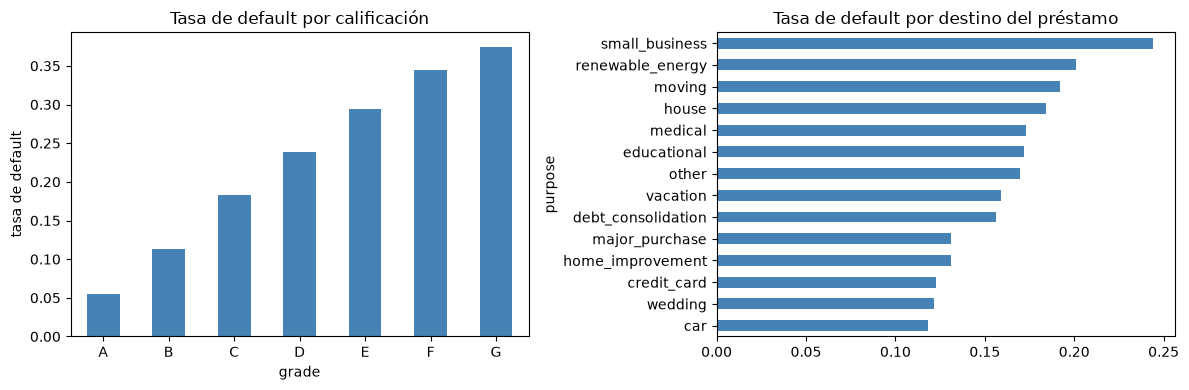

grade
A    0.055
B    0.114
C    0.183
D    0.238
E    0.294
F    0.344
G    0.375
Name: target, dtype: float64
purpose
car                   0.118
wedding               0.121
credit_card           0.122
home_improvement      0.131
major_purchase        0.131
debt_consolidation    0.156
vacation              0.159
other                 0.170
educational           0.172
medical               0.173
house                 0.184
moving                0.192
renewable_energy      0.201
small_business        0.244
Name: target, dtype: float64


In [8]:
import os
import matplotlib.pyplot as plt

os.makedirs('figuras', exist_ok=True)

completos = df[((df['term'] == 36) & (df['anio'] <= 2015)) | ((df['term'] == 60) & (df['anio'] <= 2013))]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
completos.groupby('grade')['target'].mean().plot.bar(ax=ax[0], color='steelblue', rot=0)
ax[0].set_title('Tasa de default por calificación')
ax[0].set_ylabel('tasa de default')
completos.groupby('purpose')['target'].mean().sort_values().plot.barh(ax=ax[1], color='steelblue')
ax[1].set_title('Tasa de default por destino del préstamo')
plt.tight_layout()
plt.savefig('figuras/eda.png', dpi=150)
plt.show()

print(completos.groupby('grade')['target'].mean().round(3))
print(completos.groupby('purpose')['target'].mean().sort_values().round(3))

## 3. Limpieza y codificación

Se eliminan 910 préstamos con la relación entre deuda e ingreso (`dti`) vacía, negativa o mayor a 100, o con un ingreso anual de cero o menos o de 10 millones de dólares o más. Los años de empleo, `grade` y `sub_grade` se pasan a números que respetan su orden, y los años de empleo no informados quedan en -1. La antigüedad crediticia se calcula en años, desde la primera cuenta de crédito del cliente hasta la fecha del préstamo. Los descriptivos muestran la asimetría del ingreso y del monto, y la correlación alta entre la calificación, la subcalificación y la tasa (0,95 a 0,98). La cuota depende sobre todo del monto.

El tipo de vivienda, la verificación del ingreso, el destino, el tipo de solicitud y el estado de residencia pasan a columnas de 0 y 1. Las columnas del buró están casi vacías hasta 2011 y parcialmente completas en 2012. Se conservan las 37 que tienen como máximo un 40 % de faltantes desde 2013, y en este paso los faltantes quedan sin completar. Las variables se separan en tres grupos, 46 de la solicitud, 37 del buró y 51 del estado de residencia.

In [9]:
malos = (df['dti'].isna() | df['dti'].lt(0) | df['dti'].gt(100)
         | df['annual_inc'].le(0) | df['annual_inc'].ge(10_000_000))
print(malos.sum())
df = df[~malos].copy()
len(df)

910


1344400

In [10]:
anios_emp = {'< 1 year': 0, '1 year': 1, '2 years': 2, '3 years': 3, '4 years': 4,
             '5 years': 5, '6 years': 6, '7 years': 7, '8 years': 8, '9 years': 9,
             '10+ years': 10}
df['emp_length'] = df['emp_length'].map(anios_emp).fillna(-1).astype(np.int8)

df['grade'] = df['grade'].map({g: i for i, g in enumerate('ABCDEFG', 1)}).astype(np.int8)
sub = sorted(df['sub_grade'].unique())
df['sub_grade'] = df['sub_grade'].map({s: i for i, s in enumerate(sub, 1)}).astype(np.int8)

fecha = pd.to_datetime(df['issue_d'], format='%b-%Y')
primera = pd.to_datetime(df['earliest_cr_line'], format='%b-%Y')
df['antiguedad'] = (fecha - primera).dt.days / 365.25

df[['emp_length', 'grade', 'sub_grade', 'antiguedad']].describe().round(1)

,emp_length,grade,sub_grade,antiguedad
count,1344400.0,1344400.0,1344400.0,1344400.0
mean,5.6,2.7,11.7,16.3
std,3.9,1.3,6.4,7.5
min,-1.0,1.0,1.0,3.0
25%,2.0,2.0,7.0,11.2
50%,6.0,3.0,11.0,14.7
75%,10.0,3.0,15.0,20.0
max,10.0,7.0,35.0,83.2


In [11]:
num = ['loan_amnt', 'annual_inc', 'dti', 'fico_range_low', 'int_rate', 'revol_util', 'antiguedad']
print(df[num].describe().T[['mean', '50%', 'min', 'max']].round(1))
print(df[num].skew().round(2))
df[['grade', 'sub_grade', 'int_rate', 'installment', 'fico_range_low']].corr().round(2)

                   mean      50%    min        max
loan_amnt       14416.9  12000.0  500.0    40000.0
annual_inc      76286.7  65000.0  430.0  9550000.0
dti                18.2     17.6    0.0      100.0
fico_range_low    696.2    690.0  625.0      845.0
int_rate           13.2     12.7    5.3       31.0
revol_util         51.8     52.2    0.0      892.3
antiguedad         16.3     14.7    3.0       83.2
loan_amnt          0.78
annual_inc        44.73
dti                0.53
fico_range_low     1.29
int_rate           0.71
revol_util        -0.04
antiguedad         1.09
dtype: float64


,grade,sub_grade,int_rate,installment,fico_range_low
grade,1.00,0.98,0.95,0.14,-0.41
sub_grade,0.98,1.00,0.98,0.15,-0.42
int_rate,0.95,0.98,1.00,0.15,-0.41
installment,0.14,0.15,0.15,1.00,0.05
fico_range_low,-0.41,-0.42,-0.41,0.05,1.00


In [12]:
categoricas = ['home_ownership', 'verification_status', 'purpose', 'application_type', 'addr_state']
df = pd.get_dummies(df, columns=categoricas, dtype=np.int8)
df.shape

(1344400, 158)

In [13]:
fuera = ['loan_status', 'target', 'issue_d', 'earliest_cr_line', 'anio'] + pagos

buro_df = [c for c in buro if c in df.columns and c not in base]
faltan = df.loc[df['anio'] >= 2013, buro_df].isna().mean()
buro_ok = faltan[faltan <= 0.40].index.tolist()

estado = [c for c in df.columns if c.startswith('addr_state_')]
solicitud = [c for c in df.columns if c not in fuera + buro_df + estado]

print(len(solicitud), len(buro_ok), len(estado))

46 37 51


## 4. Particiones temporales por plazo

Para 36 meses se entrena con las cohortes 2007 a 2013, se valida con la de 2014 y se prueba con la de 2015. Para 60 meses se entrena con 2010 y 2011, se valida con 2012 y se prueba con 2013. La validación se usa para elegir el corte de aprobación y para comparar modelos y grupos de variables, y la cohorte de prueba se usa para medir el resultado final. El entrenamiento de 60 meses tiene 10.690 préstamos, contra 172.988 del de 36 meses.

In [14]:
tracks = {36: 2015, 60: 2013}
datos = {}
for plazo, anio_test in tracks.items():
    d = df[df['term'] == plazo]
    datos[plazo] = {
        'train': d[d['anio'] < anio_test - 1],
        'valid': d[d['anio'] == anio_test - 1],
        'test': d[d['anio'] == anio_test],
    }
    print(plazo, {k: (len(v), round(v['target'].mean(), 3)) for k, v in datos[plazo].items()})

36 {'train': (172988, np.float64(0.124)), 'valid': (162570, np.float64(0.137)), 'test': (283019, np.float64(0.149))}
60 {'train': (10690, np.float64(0.229)), 'valid': (9897, np.float64(0.277)), 'test': (34382, np.float64(0.251))}


In [15]:
variables = solicitud + buro_ok + estado
final = solicitud + buro_ok

def xy(plazo, parte, cols=variables):
    d = datos[plazo][parte]
    return d[cols], d['target']

X_tr, y_tr = xy(36, 'train')
X_tr.shape

(172988, 134)

## 5. Costo de los errores y ganancia neta

Para un préstamo en default, la pérdida es el monto prestado menos todo lo que el cliente llegó a pagar. Para un préstamo pagado por completo, el valor es el interés que pagó, que se deja de cobrar si se lo rechaza. La ganancia neta de una regla de aprobación es el interés de los buenos pagadores aprobados menos la pérdida de los defaults aprobados, en millones de dólares. La última celda calcula el caso de aprobar todas las solicitudes a 36 meses de 2015.

In [16]:
for plazo in datos:
    for parte in datos[plazo]:
        d = datos[plazo][parte].copy()
        d['perdida'] = np.where(d['target'] == 1, d['loan_amnt'] - d['total_pymnt'], 0)
        d['interes'] = np.where(d['target'] == 0, d['total_rec_int'], 0)
        datos[plazo][parte] = d

t = datos[36]['test']
print(t.loc[t['target'] == 1, 'perdida'].mean(), t.loc[t['target'] == 0, 'interes'].mean())

4664.4175 1800.4052


In [17]:
def resultado(d, aprueba):
    perdida = d.loc[aprueba, 'perdida'].sum()
    interes = d.loc[aprueba, 'interes'].sum()
    return {'aprobacion': aprueba.mean(),
            'perdida_MUSD': perdida / 1e6,
            'ganancia_MUSD': (interes - perdida) / 1e6}

print('monto otorgado en 2015 a 36 meses (millones):', round(t['loan_amnt'].sum() / 1e6, 1))
resultado(t, np.ones(len(t), dtype=bool))

monto otorgado en 2015 a 36 meses (millones): 3624.2


{'aprobacion': np.float64(1.0),
 'perdida_MUSD': np.float32(196.51657),
 'ganancia_MUSD': np.float32(237.17943)}

## 6. Regla A-G como referencia

La regla de referencia ordena las solicitudes por `sub_grade`, de A1 a G5, y aprueba de la mejor a la peor. Para cada uno de los 35 niveles se calcula la ganancia neta en validación y en prueba. El corte que más gana en validación aprueba prácticamente todas las solicitudes.

In [18]:
def curva_ag(d):
    filas = []
    for k in range(1, 36):
        r = resultado(d, (d['sub_grade'] <= k).values)
        r['sub_grade'] = k
        filas.append(r)
    return pd.DataFrame(filas).set_index('sub_grade')

ag_val = curva_ag(datos[36]['valid'])
ag_test = curva_ag(datos[36]['test'])
ag_test.round(3)

,aprobacion,perdida_MUSD,ganancia_MUSD
sub_grade,,,
1,0.044,1.611000,11.281000
2,0.084,4.025000,22.142000
3,0.123,6.743000,33.153999
4,0.176,11.437000,48.487999
5,0.248,18.952000,69.872002
6,0.310,25.938999,86.060997
7,0.375,34.368999,103.188004
8,0.440,44.730999,121.067001
9,0.504,54.742001,138.313004


In [19]:
k_ag = ag_val['ganancia_MUSD'].idxmax()
print('corte A-G elegido en validación:', k_ag)
print('mejor corte posible en test:', ag_test['ganancia_MUSD'].idxmax())
ag_test.loc[k_ag]

corte A-G elegido en validación: 34
mejor corte posible en test: 26


aprobacion         0.999979
perdida_MUSD     196.501053
ganancia_MUSD    237.187393
Name: 34, dtype: float64

## 7. Modelos de referencia

Se entrenan una regresión logística con peso de clases balanceado y un gradient boosting (`HistGradientBoostingClassifier`) con búsqueda en grilla (GridSearchCV) de 8 combinaciones, validación cruzada de 3 particiones y el AUC como métrica. Los dos usan los préstamos a 36 meses y todas las variables. La función `evaluar` elige en la validación el corte de aprobación que más gana y calcula el Gini (2 × AUC − 1) y la ganancia aprobando el 80 % de las solicitudes, en validación y en prueba. En los dos modelos el corte elegido aprueba prácticamente todo, por eso desde la sección 8 las comparaciones se hacen a tasas de aprobación fijas.

In [20]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

def al_80(d, p):
    return resultado(d, p <= np.quantile(p, 0.8))['ganancia_MUSD']

def evaluar(nombre, modelo, plazo=36, cols=variables):
    X, y = xy(plazo, 'train', cols)
    modelo.fit(X, y)
    va, te = datos[plazo]['valid'], datos[plazo]['test']
    p_va = modelo.predict_proba(va[cols])[:, 1]
    p_te = modelo.predict_proba(te[cols])[:, 1]
    cortes = np.quantile(p_va, np.linspace(0.5, 1, 51))
    gan = [resultado(va, p_va <= c)['ganancia_MUSD'] for c in cortes]
    corte = cortes[int(np.argmax(gan))]
    r = resultado(te, p_te <= corte)
    r['gini_val'] = 2 * roc_auc_score(va['target'], p_va) - 1
    r['ganancia_80_val'] = al_80(va, p_va)
    r['auc'] = roc_auc_score(te['target'], p_te)
    r['gini'] = 2 * r['auc'] - 1
    r['ganancia_80'] = al_80(te, p_te)
    return pd.Series(r, name=nombre), p_te

logistica = make_pipeline(SimpleImputer(strategy='median', add_indicator=True),
                          StandardScaler(),
                          LogisticRegression(class_weight='balanced', max_iter=1000))
res_log, p_log = evaluar('logistica', logistica)
res_log.round(3)

aprobacion           1.000
perdida_MUSD       196.462
ganancia_MUSD      237.195
gini_val             0.353
ganancia_80_val    159.727
auc                  0.687
gini                 0.375
ganancia_80        218.545
Name: logistica, dtype: float64

In [21]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

grilla = {'learning_rate': [0.05, 0.1],
          'max_leaf_nodes': [15, 31],
          'max_iter': [200, 400]}
busqueda = GridSearchCV(HistGradientBoostingClassifier(random_state=42),
                        grilla, cv=3, scoring='roc_auc', n_jobs=2)
res_gb, p_gb = evaluar('boosting', busqueda)
print(busqueda.best_params_, '| árboles con early stopping:', busqueda.best_estimator_.n_iter_)
res_gb.round(3)

{'learning_rate': 0.05, 'max_iter': 200, 'max_leaf_nodes': 31} | árboles con early stopping: 135


aprobacion           1.000
perdida_MUSD       196.514
ganancia_MUSD      237.182
gini_val             0.374
ganancia_80_val    160.877
auc                  0.695
gini                 0.390
ganancia_80        220.104
Name: boosting, dtype: float64

In [22]:
va, te = datos[36]['valid'], datos[36]['test']
auc_ag_val = roc_auc_score(va['target'], va['sub_grade'])
auc_ag = roc_auc_score(te['target'], te['sub_grade'])

rng_ag = np.random.default_rng(42)
ag_80 = {}
for parte, d_ in [('validación', va), ('prueba', te)]:
    ag_80[parte] = al_80(d_, d_['sub_grade'].values + rng_ag.random(len(d_)))
print('regla A-G aprobando el 80 %:', {k: round(v, 1) for k, v in ag_80.items()})

tabla = pd.DataFrame([res_log, res_gb])
tabla.loc['regla A-G', ['gini_val', 'auc', 'gini']] = [2 * auc_ag_val - 1, auc_ag, 2 * auc_ag - 1]
tabla[['gini_val', 'auc', 'gini', 'aprobacion', 'ganancia_MUSD']].round(3)

regla A-G aprobando el 80 %: {'validación': np.float32(151.6), 'prueba': np.float32(205.8)}


,gini_val,auc,gini,aprobacion,ganancia_MUSD
logistica,0.353,0.687,0.375,1.0,237.195
boosting,0.374,0.695,0.390,1.0,237.182
regla A-G,0.319,0.679,0.357,NaN,NaN


## 8. Aporte de cada grupo de variables

Se entrena el mismo gradient boosting sin el buró, sin el estado de residencia y sin las variables de la calificación de Lending Club. Esas variables son `grade`, `sub_grade`, la tasa `int_rate`, que se fija según la calificación, y la cuota `installment`, que sale de la tasa. Las decisiones se toman con los resultados de validación. Sin el estado de residencia el modelo da prácticamente lo mismo, así que desde acá los modelos usan solo las variables de la solicitud y del buró (`final`).

In [23]:
params = busqueda.best_params_

variantes = {
    'completo': variables,
    'sin buró': solicitud + estado,
    'sin estado': final,
}
filas = []
for nombre, cols in variantes.items():
    m = HistGradientBoostingClassifier(random_state=42, **params)
    r, p = evaluar(nombre, m, cols=cols)
    filas.append(r)

aporte = pd.DataFrame(filas)
aporte[['gini_val', 'ganancia_80_val', 'gini', 'ganancia_80']].round(3)

,gini_val,ganancia_80_val,gini,ganancia_80
completo,0.374,160.877,0.390,220.104
sin buró,0.353,158.549,0.368,215.132
sin estado,0.372,160.627,0.389,219.913


In [24]:
sin_calif = [c for c in final if c not in ['grade', 'sub_grade', 'int_rate', 'installment']]
m = HistGradientBoostingClassifier(random_state=42, **params)
r, p_sin = evaluar('sin calificación', m, cols=sin_calif)
aporte.loc['sin calificación'] = r
aporte[['gini_val', 'ganancia_80_val', 'gini', 'ganancia_80']].round(3)

,gini_val,ganancia_80_val,gini,ganancia_80
completo,0.374,160.877,0.390,220.104
sin buró,0.353,158.549,0.368,215.132
sin estado,0.372,160.627,0.389,219.913
sin calificación,0.356,161.396,0.366,219.730


## 9. Redes neuronales densas

Se entrenan dos redes con Keras sobre las mismas particiones y con las variables `final`, una con una capa oculta de 16 neuronas y otra con capas de 64 y 32 neuronas y dropout de 0,3. Las dos usan peso de clases, early stopping sobre un 20 % del entrenamiento elegido al azar y semillas fijas para que el resultado se repita entre corridas. La tabla final las compara con la regresión logística y el gradient boosting entrenados con las mismas variables.

In [25]:
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
from tensorflow import keras
import tensorflow as tf

keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

class Red:
    def __init__(self, capas, dropout=0.0):
        self.capas = capas
        self.dropout = dropout

    def fit(self, X, y):
        self.prep = make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler())
        Xp = self.prep.fit_transform(X)
        orden = np.random.default_rng(42).permutation(len(Xp))
        Xp, y = Xp[orden], np.asarray(y)[orden]
        self.m = keras.Sequential([keras.Input(shape=(Xp.shape[1],))])
        for n in self.capas:
            self.m.add(keras.layers.Dense(n, activation='relu'))
            if self.dropout:
                self.m.add(keras.layers.Dropout(self.dropout))
        self.m.add(keras.layers.Dense(1, activation='sigmoid'))
        self.m.compile(optimizer='adam', loss='binary_crossentropy', metrics=[keras.metrics.AUC(name='auc')])
        peso = {0: 1.0, 1: (y == 0).sum() / (y == 1).sum()}
        parar = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=3, restore_best_weights=True)
        self.m.fit(Xp, y, epochs=20, batch_size=1024, validation_split=0.2,
                   class_weight=peso, callbacks=[parar], verbose=0)
        return self

    def predict_proba(self, X):
        p = self.m.predict(self.prep.transform(X), verbose=0).ravel()
        return np.column_stack([1 - p, p])

res_red1, p_red1 = evaluar('red simple', Red([16]), cols=final)
res_red1.round(3)

aprobacion           1.000
perdida_MUSD       196.517
ganancia_MUSD      237.177
gini_val             0.357
ganancia_80_val    159.374
auc                  0.691
gini                 0.382
ganancia_80        218.589
Name: red simple, dtype: float64

In [26]:
keras.utils.set_random_seed(42)
res_red2, p_red2 = evaluar('red compleja', Red([64, 32], dropout=0.3), cols=final)
res_log2, p_log2 = evaluar('logistica', logistica, cols=final)

comp = pd.DataFrame([res_log2, aporte.loc['sin estado'].rename('boosting'), res_red1, res_red2])
comp[['gini_val', 'ganancia_80_val', 'auc', 'gini', 'ganancia_80']].round(3)

,gini_val,ganancia_80_val,auc,gini,ganancia_80
logistica,0.351,159.603,0.688,0.376,218.144
boosting,0.372,160.627,0.695,0.389,219.913
red simple,0.357,159.374,0.691,0.382,218.589
red compleja,0.366,160.198,0.695,0.389,218.604


## 10. Comparación a igual tasa de aprobación

Se entrena el gradient boosting final, sin estado de residencia, y se compara su Gini en entrenamiento, validación y prueba. El early stopping lo detiene en 129 árboles; el de la sección 7, con el estado de residencia, se detenía en 135. Después se ordenan los préstamos de 2015 con tres puntajes, la regla A-G, el boosting y el boosting sin calificación, y cada uno aprueba el 70, el 80 y el 90 % de las solicitudes. Los empates dentro de un mismo `sub_grade` se resuelven al azar. Un bootstrap de 1.000 remuestreos da el intervalo de la diferencia de ganancia entre el boosting y la regla A-G.

Al 80 % de aprobación se comparan los préstamos que aprueba una regla y rechaza la otra, la aprobación por calificación y la matriz de confusión, contando el rechazo como predicción de default.

In [27]:
gb = HistGradientBoostingClassifier(random_state=42, **params)
res_final, p_final = evaluar('boosting final', gb, cols=final)

X_tr, y_tr = xy(36, 'train', final)
print('Gini entrenamiento:', round(2 * roc_auc_score(y_tr, gb.predict_proba(X_tr)[:, 1]) - 1, 3),
      '| validación:', round(res_final['gini_val'], 3), '| prueba:', round(res_final['gini'], 3))
print('árboles:', gb.n_iter_, '| default predicho promedio:', round(p_final.mean(), 3),
      '| observado:', round(te['target'].mean(), 3))

rng = np.random.default_rng(42)
puntajes = {
    'regla A-G': te['sub_grade'].values + rng.random(len(te)),
    'boosting': p_final,
    'boosting sin calificación': p_sin,
}

def aprobar(puntaje, tasa):
    n = int(round(tasa * len(puntaje)))
    aprueba = np.zeros(len(puntaje), dtype=bool)
    aprueba[np.argsort(puntaje)[:n]] = True
    return aprueba

filas = []
for tasa in [0.7, 0.8, 0.9]:
    for nombre, s in puntajes.items():
        r = resultado(te, aprobar(s, tasa))
        r['tasa'], r['regla'] = tasa, nombre
        filas.append(r)

curva = pd.DataFrame(filas)
curva.pivot(index='regla', columns='tasa', values=['ganancia_MUSD', 'perdida_MUSD']).round(1)

Gini entrenamiento: 0.449 | validación: 0.372 | prueba: 0.389
árboles: 129 | default predicho promedio: 0.118 | observado: 0.149


ganancia_MUSD                         perdida_MUSD  \
tasa                                0.7         0.8         0.9          0.7   
regla                                                                          
boosting                     201.600006  219.899994  233.600006    96.300003   
boosting sin calificación    200.899994  219.699997  233.899994   100.199997   
regla A-G                    183.600006  205.800003  225.100006    95.300003   

                                                   
tasa                              0.8         0.9  
regla                                              
boosting                   121.599998  152.800003  
boosting sin calificación  124.900002  154.300003  
regla A-G                  121.699997  152.600006

In [28]:
gan = te['interes'].values - te['perdida'].values
aprob = {t: (aprobar(puntajes['regla A-G'], t), aprobar(p_final, t)) for t in [0.7, 0.8, 0.9]}
rng_b = np.random.default_rng(0)
dif = {t: [] for t in aprob}
for _ in range(1000):
    i = rng_b.integers(0, len(te), len(te))
    for t, (a_ag, a_m) in aprob.items():
        dif[t].append(((gan[i] * a_m[i]).sum() - (gan[i] * a_ag[i]).sum()) / 1e6)

pd.DataFrame({t: np.percentile(v, [2.5, 50, 97.5]) for t, v in dif.items()},
             index=['2,5 %', 'mediana', '97,5 %']).round(1)

,0.7,0.8,0.9
"2,5 %",16.5,12.5,7.0
mediana,18.0,14.0,8.5
"97,5 %",19.6,15.6,9.9


In [29]:
a = aprobar(puntajes['regla A-G'], 0.8)
b = aprobar(puntajes['boosting'], 0.8)
d = te.assign(ag=a, modelo=b)

salen = d[d['ag'] & ~d['modelo']]
entran = d[~d['ag'] & d['modelo']]
for nombre, g in [('salen', salen), ('entran', entran)]:
    print(nombre, len(g), '| default:', round(g['target'].mean(), 3),
          '| tasa:', round(g['int_rate'].mean(), 1),
          '| monto promedio:', round(g['loan_amnt'].mean()),
          '| pérdida:', round(g['perdida'].sum() / 1e6, 1),
          '| interés:', round(g['interes'].sum() / 1e6, 1),
          '| pérdida sobre monto en defaults:', round(g.loc[g['target'] == 1, 'perdida'].sum() / g.loc[g['target'] == 1, 'loan_amnt'].sum(), 3))
    print('   calificación:', (g['grade'].value_counts(normalize=True).sort_index() * 100).round(1).to_dict())

d.groupby('grade')[['ag', 'modelo']].mean().round(3)

salen 19547 | default: 0.249 | tasa: 12.8 | monto promedio: 10167 | pérdida: 18.8 | interés: 25.3 | pérdida sobre monto en defaults: 0.374
   calificación: {1: 0.2, 2: 17.2, 3: 82.6}
entran 19547 | default: 0.194 | tasa: 15.9 | monto promedio: 12629 | pérdida: 18.7 | interés: 39.3 | pérdida sobre monto en defaults: 0.378
   calificación: {3: 36.9, 4: 55.9, 5: 6.7, 6: 0.4, 7: 0.0}


,ag,modelo
grade,,
1,1.000,0.999
2,1.000,0.963
3,0.834,0.719
4,0.000,0.334
5,0.000,0.140
6,0.000,0.054
7,0.000,0.016


In [30]:
from sklearn.metrics import confusion_matrix, classification_report

for nombre, aprueba in [('regla A-G', a), ('boosting', b)]:
    rechaza = (~aprueba).astype(int)
    print(nombre)
    print(confusion_matrix(te['target'], rechaza))
    print(classification_report(te['target'], rechaza, target_names=['paga', 'default'], digits=3))

regla A-G


[[199506  41382]
 [ 26909  15222]]
              precision    recall  f1-score   support

        paga      0.881     0.828     0.854    240888
     default      0.269     0.361     0.308     42131

    accuracy                          0.759    283019
   macro avg      0.575     0.595     0.581    283019
weighted avg      0.790     0.759     0.773    283019

boosting
[[200581  40307]
 [ 25834  16297]]
              precision    recall  f1-score   support

        paga      0.886     0.833     0.858    240888
     default      0.288     0.387     0.330     42131

    accuracy                          0.766    283019
   macro avg      0.587     0.610     0.594    283019
weighted avg      0.797     0.766     0.780    283019



## 11. Importancia de las variables

La importancia por permutación se calcula sobre 50.000 préstamos de 2015 y los valores SHAP sobre 5.000. Los valores SHAP están en la escala de salida del modelo (log-odds). La última celda compara el valor SHAP promedio de los años de empleo según el valor informado.

In [31]:
from sklearn.inspection import permutation_importance

muestra = te.sample(50_000, random_state=42)
imp = permutation_importance(gb, muestra[final], muestra['target'], scoring='roc_auc',
                             n_repeats=3, random_state=42, n_jobs=2)
importancia = pd.Series(imp.importances_mean, index=final).sort_values(ascending=False)
importancia.head(15).round(4)

int_rate                 0.0199
sub_grade                0.0119
annual_inc               0.0117
acc_open_past_24mths     0.0084
loan_amnt                0.0081
installment              0.0045
dti                      0.0044
fico_range_low           0.0022
emp_length               0.0019
mths_since_recent_bc     0.0019
revol_bal                0.0018
home_ownership_RENT      0.0014
mths_since_recent_inq    0.0013
revol_util               0.0013
total_bc_limit           0.0013
dtype: float64

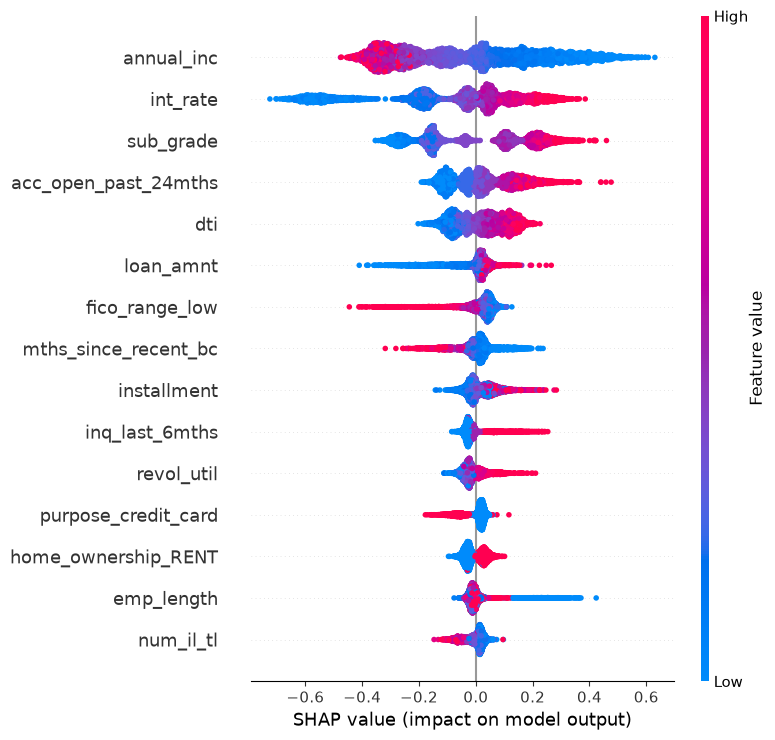

In [32]:
import shap

chica = muestra.sample(5_000, random_state=42)
explicador = shap.TreeExplainer(gb)
valores = explicador.shap_values(chica[final])
shap.summary_plot(valores, chica[final], max_display=15, show=False)
plt.savefig('figuras/shap.png', dpi=150, bbox_inches='tight')
plt.show()

In [33]:
i = final.index('emp_length')
emp = pd.DataFrame({'emp_length': chica['emp_length'].values, 'shap': valores[:, i]})
emp.groupby('emp_length')['shap'].agg(['count', 'mean']).round(3)

,count,mean
emp_length,,
-1,318,0.239
0,387,-0.003
1,335,-0.007
2,434,-0.011
3,422,-0.012
4,302,-0.021
5,299,-0.019
6,222,-0.009
7,198,-0.008


## 12. Estabilidad por año y préstamos a 60 meses

Para cada año entre 2012 y 2015 se entrena el boosting con todas las cohortes anteriores a 36 meses y se prueba en ese año, aprobando el 80 %. En cada año se dejan afuera las columnas sin datos en el entrenamiento. Para 60 meses se entrena un boosting nuevo con 2010 y 2011, con los mismos hiperparámetros, se valida con 2012 y se prueba con 2013. En esos años solo 4 columnas del buró tienen datos.

In [34]:
cols = final + ['target', 'anio', 'total_pymnt', 'total_rec_int']
d36 = df.loc[(df['term'] == 36) & (df['anio'] <= 2015), cols].copy()
d36['perdida'] = np.where(d36['target'] == 1, d36['loan_amnt'] - d36['total_pymnt'], 0)
d36['interes'] = np.where(d36['target'] == 0, d36['total_rec_int'], 0)

filas = []
for anio in [2012, 2013, 2014, 2015]:
    tr = d36[d36['anio'] < anio]
    ts = d36[d36['anio'] == anio]
    usar = [c for c in final if tr[c].notna().any()]
    m = HistGradientBoostingClassifier(random_state=42, **params).fit(tr[usar], tr['target'])
    p = m.predict_proba(ts[usar])[:, 1]
    ag = ts['sub_grade'].values + rng.random(len(ts))
    filas.append({'anio': anio, 'prestamos': len(ts),
                  'gini_modelo': 2 * roc_auc_score(ts['target'], p) - 1,
                  'gini_AG': 2 * roc_auc_score(ts['target'], ts['sub_grade']) - 1,
                  'ganancia_modelo': resultado(ts, aprobar(p, 0.8))['ganancia_MUSD'],
                  'ganancia_AG': resultado(ts, aprobar(ag, 0.8))['ganancia_MUSD']})

estab = pd.DataFrame(filas).set_index('anio')
estab.round(3)

,prestamos,gini_modelo,gini_AG,ganancia_modelo,ganancia_AG
anio,,,,,
2012,43470,0.284,0.239,43.750000,36.358002
2013,100422,0.346,0.298,121.403999,114.584999
2014,162570,0.372,0.319,160.626999,151.389999
2015,283019,0.409,0.357,220.123993,205.960999


In [35]:
d60 = datos[60]
usar = [c for c in final if d60['train'][c].notna().any()]
gb60 = HistGradientBoostingClassifier(random_state=42, **params)
res60, p60 = evaluar('boosting 60 meses', gb60, plazo=60, cols=usar)
print('columnas del buró usadas:', [c for c in usar if c in buro_ok])

t60 = d60['test']
ag60 = t60['sub_grade'].values + rng.random(len(t60))
print('Gini modelo:', round(res60['gini'], 3),
      '| Gini A-G:', round(2 * roc_auc_score(t60['target'], t60['sub_grade']) - 1, 3))
print('aprobar todo:', round(resultado(t60, np.ones(len(t60), dtype=bool))['ganancia_MUSD'], 1))
for tasa in [0.7, 0.8, 0.9]:
    print(tasa, '| modelo:', round(resultado(t60, aprobar(p60, tasa))['ganancia_MUSD'], 1),
          '| A-G:', round(resultado(t60, aprobar(ag60, tasa))['ganancia_MUSD'], 1))

columnas del buró usadas: ['acc_now_delinq', 'chargeoff_within_12_mths', 'delinq_amnt', 'tax_liens']
Gini modelo: 0.214 | Gini A-G: 0.215
aprobar todo: 140.3
0.7 | modelo: 100.1 | A-G: 94.2
0.8 | modelo: 114.6 | A-G: 110.5
0.9 | modelo: 128.2 | A-G: 126.6


## 13. Figuras para el informe

Se generan la curva de ganancia neta según la tasa de aprobación, la aprobación por calificación al 80 %, el Gini por año y la curva ROC del boosting contra la regla A-G, y se guardan en la carpeta `figuras`. Los gráficos del análisis exploratorio y de SHAP se guardan en las secciones 2 y 11.

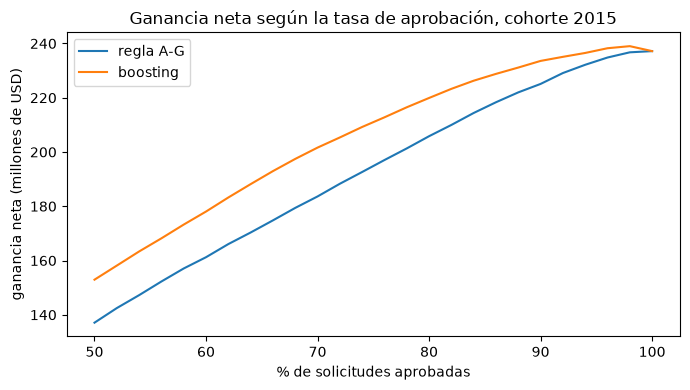

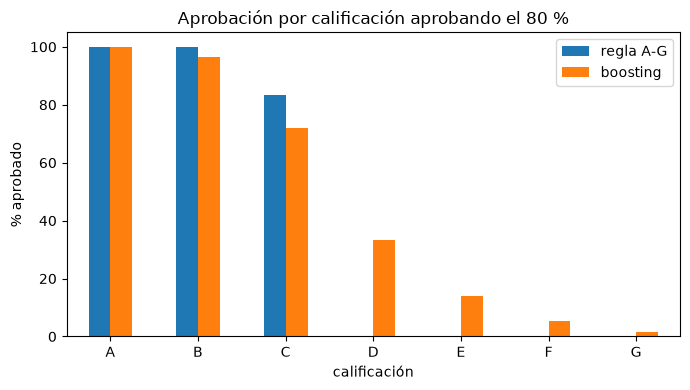

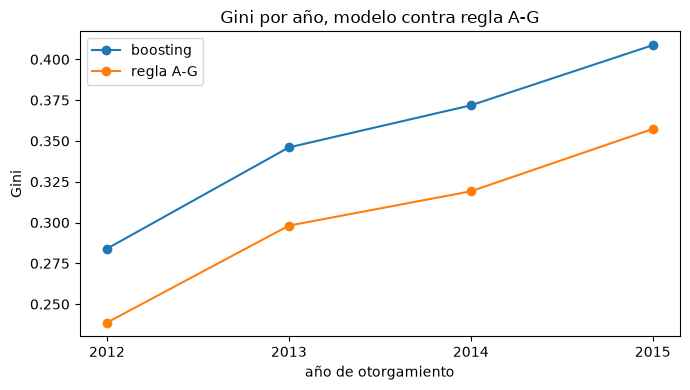

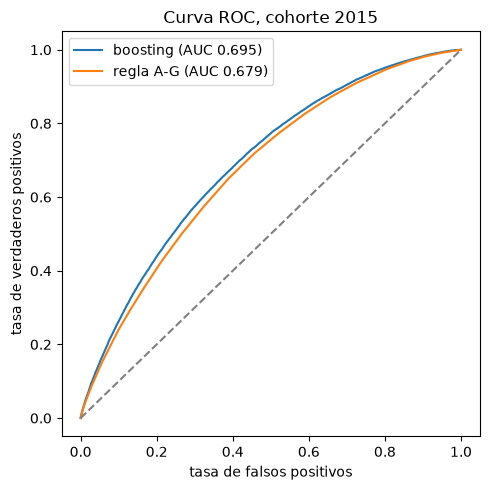

In [36]:
tasas = np.linspace(0.5, 1, 26)
fig, ax = plt.subplots(figsize=(7, 4))
for nombre in ['regla A-G', 'boosting']:
    g = [resultado(te, aprobar(puntajes[nombre], t))['ganancia_MUSD'] for t in tasas]
    ax.plot(tasas * 100, g, label=nombre)
ax.set_xlabel('% de solicitudes aprobadas')
ax.set_ylabel('ganancia neta (millones de USD)')
ax.set_title('Ganancia neta según la tasa de aprobación, cohorte 2015')
ax.legend()
plt.tight_layout()
plt.savefig('figuras/curva_ganancia.png', dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
(d.groupby('grade')[['ag', 'modelo']].mean() * 100).rename(index=dict(enumerate('ABCDEFG', 1))).plot.bar(ax=ax, rot=0)
ax.set_xlabel('calificación')
ax.set_ylabel('% aprobado')
ax.set_title('Aprobación por calificación aprobando el 80 %')
ax.legend(['regla A-G', 'boosting'])
plt.tight_layout()
plt.savefig('figuras/aprobacion_por_calificacion.png', dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
estab[['gini_modelo', 'gini_AG']].plot(ax=ax, marker='o')
ax.set_xlabel('año de otorgamiento')
ax.set_ylabel('Gini')
ax.set_title('Gini por año, modelo contra regla A-G')
ax.legend(['boosting', 'regla A-G'])
ax.set_xticks(estab.index)
plt.tight_layout()
plt.savefig('figuras/estabilidad_gini.png', dpi=150)
plt.show()

from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(5, 5))
for nombre, s in [('boosting', p_final), ('regla A-G', te['sub_grade'].values)]:
    fpr, tpr, _ = roc_curve(te['target'], s)
    ax.plot(fpr, tpr, label=f"{nombre} (AUC {roc_auc_score(te['target'], s):.3f})")
ax.plot([0, 1], [0, 1], color='gray', linestyle='--')
ax.set_xlabel('tasa de falsos positivos')
ax.set_ylabel('tasa de verdaderos positivos')
ax.set_title('Curva ROC, cohorte 2015')
ax.legend()
plt.tight_layout()
plt.savefig('figuras/roc.png', dpi=150)
plt.show()